# Phát hiện tin tuyển dụng giả mạo - Báo cáo tiến độ giữa kỳ
**Nhóm 7 - Track B**
**CRISP-DM: Data Understanding & Data Preparation.**

Notebook kiểm tra dữ liệu, phân tích giá trị thiếu, ngoại lai và mất cân bằng lớp, sau đó tạo
pipeline tiền xử lý cho văn bản và thuộc tính có cấu trúc. Chưa huấn luyện hoặc
tuyên bố hiệu quả của mô hình phân lớp. Chạy lần lượt các ô từ trên xuống.

Nguồn: https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction/data

Quy tắc: chỉ `fit` trên train; validation/test chỉ `transform`. Phân tích chi tiết
và các quyết định xử lý dựa trên train. Bản dữ liệu gốc được giữ nguyên.


## Bối cảnh nghiệp vụ và nguồn dữ liệu
Đối tượng sử dụng dự kiến là bộ phận kiểm duyệt của một nền tảng tuyển dụng.
Tại thời điểm gửi tin, hệ thống chấm điểm nghi ngờ để ưu tiên kiểm tra. Người kiểm
duyệt xác minh doanh nghiệp/nội dung và quyết định xử lý. Đây là tình huống giả định
cho đồ án; nhóm chưa có doanh nghiệp đối tác hoặc số liệu chi phí vận hành thực tế.

Mục tiêu khai phá là **phân lớp nhị phân có giám sát**, với `fraudulent=1` là lớp
quan tâm. Gom cụm/luật kết hợp không trực tiếp thay thế mục tiêu dự đoán nhãn này.

File Kaggle có 17.880 tin và 18 cột; 17.014 tin nhãn 0, 866 tin nhãn 1 (4,84%).
Một dòng là một tin đăng, không phải một ứng viên hay một doanh nghiệp.
Bộ EMSCAD được mô tả trong nghiên cứu Vidros và cộng sự (2017), từ tin Workable
giai đoạn 2012–2014, gán nhãn thủ công bởi nhân sự chuyên trách. CSV Kaggle là bản
phân phối thứ cấp; nhóm dùng nhãn công bố, chưa xác minh lại từng tin với Workable.
Không diễn giải tỷ lệ 4,84% là tỷ lệ gian lận của thị trường hiện tại.

File không có thời điểm đăng hay ID doanh nghiệp ổn định để kiểm định theo thời gian/
doanh nghiệp. Demo giới hạn nội dung tiếng Anh tương tự dữ liệu nghiên cứu, chưa
khẳng định hiệu quả với tin tiếng Việt. Không đọc điểm mô hình là xác suất đã hiệu chuẩn.

Nguồn: [Kaggle](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction/data);
[Vidros et al., 2017](https://doi.org/10.3390/fi9010006).


## 0. Chuẩn bị môi trường
Sử dụng Python 3.12 và các phiên bản trong `requirements_midterm.txt`.
Để cài trong Jupyter, bỏ dấu `#` ở dòng `%pip`, chạy ô lệnh, sau đó khởi động lại
kernel và chọn Run All. Không chạy tiếp với kernel đang giữ phiên bản cũ.

Cần cố định phiên bản thư viện để tái lập cách chia nhóm và kết quả đặc trưng.
Cùng `random_state` không bảo đảm kết quả giống nhau giữa các phiên bản scikit-learn.


In [1]:
# %pip install "pandas==2.3.3" "numpy==2.5.3" "scipy==1.16.3" "scikit-learn==1.7.2" "matplotlib==3.11.2" "seaborn==0.13.2" "ipykernel>=6,<7"


## 1. Import và cấu hình
Dữ liệu nằm trong data/ của bộ nộp. Các minh chứng được lưu vào
midterm_artifacts/ ở thư mục gốc; file CSV nguồn không bị sửa.


In [2]:
from pathlib import Path
import hashlib
import html
import io
import json
import platform
import re
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Tìm thư mục bộ nộp từ vị trí script hoặc thư mục làm việc của notebook.
# Hỗ trợ chạy tại thư mục gốc hoặc tại code/ sau khi giải nén.
START_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
PROJECT_DIR = next((p for p in (START_DIR, *START_DIR.parents)
                    if (p / "data" / "fake_job_postings.csv").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Hãy chạy notebook từ thư mục bộ nộp hoặc code/; cần data/fake_job_postings.csv.")
DATA_PATH = PROJECT_DIR / "data" / "fake_job_postings.csv"
ARTIFACT_DIR = PROJECT_DIR / "midterm_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
TARGET = "fraudulent"
ID_COLUMN = "job_id"
TEXT_COLUMNS = ["title", "company_profile", "description", "requirements", "benefits"]
BINARY_COLUMNS = ["telecommuting", "has_company_logo", "has_questions"]
CATEGORICAL_COLUMNS = [
    "department", "employment_type", "required_experience",
    "required_education", "industry", "function", "country",
]
COUNT_COLUMNS = [f"{c}_word_count" for c in TEXT_COLUMNS]
NUMERIC_COLUMNS = [f"log1p_{c}" for c in COUNT_COLUMNS]
MISSING_FLAGS = [f"{c}_missing" for c in TEXT_COLUMNS + ["salary_range"]]
FLAG_COLUMNS = BINARY_COLUMNS + MISSING_FLAGS

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 85)


def save_table(table, filename):
    """Lưu bảng minh chứng bằng UTF-8 BOM để có thể mở tiếng Việt trong Excel."""
    table.to_csv(ARTIFACT_DIR / filename, index=True, encoding="utf-8-sig")


def finish_figure(fig, filename):
    """Lưu hình rõ nét, hiển thị trong notebook và giải phóng bộ nhớ hình."""
    fig.tight_layout()
    fig.savefig(ARTIFACT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


versions = {name: metadata.version(name) for name in [
    "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn"
]}
print("Python:", platform.python_version())
display(pd.Series(versions, name="Phiên bản"))

# Kiểm tra môi trường trước khi đọc dữ liệu để tránh lệch kết quả giữa các lần chạy.
EXPECTED_VERSIONS = {
    "pandas": "2.3.3", "numpy": "2.5.3", "scipy": "1.16.3",
    "scikit-learn": "1.7.2", "matplotlib": "3.11.2", "seaborn": "0.13.2",
}
version_mismatches = {
    name: (versions[name], expected) for name, expected in EXPECTED_VERSIONS.items()
    if versions[name] != expected
}
if version_mismatches:
    raise RuntimeError(
        "Phiên bản thư viện không khớp bộ nộp: " + str(version_mismatches)
        + ". Cài requirements_midterm.txt, khởi động lại kernel rồi Run All."
    )


Python: 3.12.14


pandas           2.3.3
numpy            2.5.3
scipy           1.16.3
scikit-learn     1.7.2
matplotlib      3.11.2
seaborn         0.13.2
Name: Phiên bản, dtype: object

## 2. Đọc dữ liệu và tổng quan
`job_id` là mã định danh, không phải biến đo lường. Ba cờ 0/1 là biến nhị phân.
`salary_range` chứa chuỗi khoảng lương; thiếu thông tin chuẩn hóa đơn vị/kỳ trả
lương nên không tự chuyển các khoảng này thành một biến thu nhập có thể so sánh.
`describe()` của mã ID/cờ nhị phân chỉ giúp kiểm tra dữ liệu, không diễn giải như
phân phối của đại lượng liên tục.


Dataset gốc: **17.880 dòng × 18 cột**. Mỗi dòng là một tin tuyển dụng;
18 cột gồm 1 ID, 1 nhãn và 16 trường thông tin đầu vào. Bảng xem trước bên dưới
lấy 5 dòng đầu, đủ 18 cột. Đây không phải mẫu đại diện cho tỷ lệ lớp.


In [3]:
def load_data(path):
    """Đọc CSV và kiểm tra lược đồ tối thiểu, không học thống kê từ dữ liệu."""
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy {path}. Hãy sửa DATA_PATH.")
    data = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    expected = set(TEXT_COLUMNS + BINARY_COLUMNS + [
        ID_COLUMN, TARGET, "location", "salary_range",
    ] + [c for c in CATEGORICAL_COLUMNS if c != "country"])
    missing_columns = expected - set(data.columns)
    if missing_columns:
        raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")
    return data


def show_overview(data):
    """Trình bày shape, info, describe số và describe phi số theo yêu cầu rubric."""
    print(f"Số dòng: {data.shape[0]:,}; số cột: {data.shape[1]}")
    print("Xem trước 5 dòng đầu; hiển thị đủ 18 cột (ô văn bản dài được rút gọn khi xem):")
    with pd.option_context("display.max_columns", None):
        display(data.head(5))
    # CSV minh chứng giữ đủ cột và nội dung gốc, không cắt ngắn văn bản.
    data.head(5).to_csv(ARTIFACT_DIR / "01_preview_raw_5rows.csv",
                        index=False, encoding="utf-8-sig")
    buffer = io.StringIO()
    data.info(buf=buffer, memory_usage="deep")
    print(buffer.getvalue())
    (ARTIFACT_DIR / "01_info.txt").write_text(buffer.getvalue(), encoding="utf-8")
    print("Thống kê các cột số trong dữ liệu gốc:")
    display(data.describe().T)
    print("Thống kê các cột phi số:")
    display(data.describe(include=["object", "string"]).T)


raw_data = load_data(DATA_PATH)
show_overview(raw_data)


Số dòng: 17,880; số cột: 18
Xem trước 5 dòng đầu; hiển thị đủ 18 cột (ô văn bản dài được rút gọn khi xem):


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. ...","Food52, a fast-growing, James Beard Award-winning online food community and crowd...",Experience with content management systems a major plus (any blogging counts!)Fam...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cl...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer servic...,What we expect from you:Your key responsibility will be to communicate with the c...,What you will get from usThrough being part of the 90 Seconds team you will gain:...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies acro...,"Our client, located in Houston, is actively seeking an experienced Commissioning ...",Implement pre-commissioning and commissioning procedures for rotary equipment.Exe...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life through geography is at the heart of ev...,THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for impro...,"EDUCATION: Bachelor’s or Master’s in GIS, business administration, or a related f...","Our culture is anything but corporate—we have a collaborative, creative environme...",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Capital Management Consulting firm hea...,"JOB TITLE: Itemization Review ManagerLOCATION: Fort Worth, TX ...",QUALIFICATIONS:RN license in the State of TexasDiploma or Bachelors of Science in...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

,count,mean,std,min,25%,50%,75%,max
job_id,17880.0,8940.500000,5161.655742,1.0,4470.75,8940.5,13410.25,17880.0
telecommuting,17880.0,0.042897,0.202631,0.0,0.00,0.0,0.00,1.0
has_company_logo,17880.0,0.795302,0.403492,0.0,1.00,1.0,1.00,1.0
has_questions,17880.0,0.491723,0.499945,0.0,0.00,0.0,1.00,1.0
fraudulent,17880.0,0.048434,0.214688,0.0,0.00,0.0,0.00,1.0


Thống kê các cột phi số:


,count,unique,top,freq
title,17880,11231,English Teacher Abroad,311
location,17534,3105,"GB, LND, London",718
department,6333,1337,Sales,551
salary_range,2868,874,0-0,142
company_profile,14572,1709,We help teachers get safe &amp; secure jobs abroad :),726
description,17879,14801,"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($20...",379
requirements,15184,11967,University degree required. TEFL / TESOL / CELTA or teaching experience preferred...,410
benefits,10668,6204,See job description,726
employment_type,14409,5,Full-time,11620
required_experience,10830,7,Mid-Senior level,3809


## 3. Kiểm tra chất lượng, giá trị thiếu và nhãn
Chuỗi rỗng hoặc chỉ gồm khoảng trắng được thống nhất thành `NaN` bằng quy tắc
cố định, không phải điền thiếu. Nhãn thiếu/sai không được điền bằng mode.
Báo cáo toàn bộ dữ liệu ở bước này phục vụ kiểm kê ban đầu; các ngưỡng và thống kê
dùng cho tiền xử lý sẽ chỉ được học từ train.


In [4]:
def normalize_and_validate(data):
    """Sao chép dữ liệu, chuẩn hóa khoảng trắng và kiểm tra miền giá trị."""
    result = data.copy(deep=True)
    for col in result.select_dtypes(include=["object", "string"]).columns:
        result[col] = result[col].str.strip().replace(r"^\s*$", np.nan, regex=True)
    labels = pd.to_numeric(result[TARGET], errors="coerce")
    if labels.isna().any() or not labels.isin([0, 1]).all():
        raise ValueError("Nhãn fraudulent phải có đủ và chỉ nhận 0/1; cần rà soát nguồn.")
    result[TARGET] = labels.astype("int8")
    if result[ID_COLUMN].isna().any() or result[ID_COLUMN].duplicated().any():
        raise ValueError("job_id thiếu hoặc trùng: cần xác minh trước khi chia dữ liệu.")
    for col in BINARY_COLUMNS:
        values = pd.to_numeric(result[col], errors="coerce")
        invalid = result[col].notna() & (values.isna() | ~values.isin([0, 1]))
        if invalid.any():
            raise ValueError(f"{col} có {invalid.sum()} giá trị khác 0/1.")
        result[col] = values.astype(float)
    return result


def missing_report(data):
    """Tính số lượng và phần trăm thiếu, kể cả cột không thiếu để kiểm toán."""
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "missing_count": data.isna().sum(),
        "missing_pct": data.isna().mean().mul(100),
        "unique_non_missing": data.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)


def class_report(labels):
    """Phân bố nhãn: lớp 1 là giả mạo, không nhầm với lớp đa số."""
    counts = labels.value_counts().reindex([0, 1], fill_value=0)
    report = pd.DataFrame({"count": counts, "percent": counts / len(labels) * 100})
    report.index.name = TARGET
    return report


data = normalize_and_validate(raw_data)
raw_missing = missing_report(data)
raw_classes = class_report(data[TARGET])
display(raw_missing)
display(raw_classes)
save_table(raw_missing, "02_missing_raw.csv")
save_table(raw_classes, "03_class_raw.csv")
majority_accuracy = data[TARGET].value_counts(normalize=True).max()
print(f"Accuracy nếu chỉ đoán lớp đa số: {majority_accuracy:.2%}")
print("Accuracy cao chưa đồng nghĩa phát hiện tốt tin giả; cần precision/recall/F1/PR-AUC.")


,dtype,missing_count,missing_pct,unique_non_missing
salary_range,object,15012,83.959732,874
department,object,11553,64.614094,1276
required_education,object,8105,45.329978,13
benefits,object,7220,40.380313,6079
required_experience,object,7050,39.429530,7
function,object,6455,36.101790,37
industry,object,4903,27.421700,131
employment_type,object,3471,19.412752,5
company_profile,object,3308,18.501119,1708
requirements,object,2698,15.089485,11898


,count,percent
fraudulent,,
0,17014,95.1566
1,866,4.8434


Accuracy nếu chỉ đoán lớp đa số: 95.16%
Accuracy cao chưa đồng nghĩa phát hiện tốt tin giả; cần precision/recall/F1/PR-AUC.


## 4. Kiểm tra trùng và chia train/validation/test theo nhóm nội dung
1. Các dòng có toàn bộ đặc trưng gốc giống nhau (bỏ ID/nhãn) được kiểm tra nhãn.
Nếu nhãn mâu thuẫn, tạm cách ly cả nhóm và ghi lại ID để rà soát, không chọn nhãn tùy ý.
2. Với bản sao hoàn toàn và nhãn nhất quán, chỉ giữ một dòng.
3. Nhóm tin có cùng tiêu đề + mô tả + yêu cầu sau làm sạch được giữ trong cùng tập.

Nạp manifest holdout cố định đã công bố trong checkpoint trước: khoảng 60% train,
20% validation và 20% test. Manifest được tạo bằng phân tầng theo nhóm và chỉ lấy
fold đầu, chưa sử dụng kết quả mô hình. Kích thước/tỷ lệ lớp không bằng nhau tuyệt đối.
Kiểm tra lại hash dữ liệu, ID, khóa nhóm và giao nhau mỗi lần chạy. Không chia lại test
để tìm phân bố thuận lợi hơn. CV trên train dùng thuật toán xác định ở mục 4b.
Cách này chưa loại hết tin gần trùng theo ngữ nghĩa hoặc trùng công ty.


In [5]:
def clean_text(value):
    """Làm sạch xác định theo từng ô: không học từ các dòng khác hoặc từ nhãn.

    Giữ từ phủ định và dấu câu; TF-IDF sẽ tách token. Không cần tải NLTK/spaCy.
    URL/email/số điện thoại không được xác minh; đây chỉ là biểu diễn văn bản.
    """
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip().lower()


def content_groups(frame):
    """Khóa nhóm chỉ từ X, tuyệt đối không dùng fraudulent hoặc ID làm tín hiệu."""
    cols = ["title", "description", "requirements"]
    normalized = frame[cols].apply(lambda col: col.map(clean_text))
    # JSON giữ ranh giới giữa các trường, SHA-256 tạo khóa gọn và ổn định.
    return normalized.apply(
        lambda row: hashlib.sha256(
            json.dumps(row.tolist(), ensure_ascii=False).encode("utf-8")
        ).hexdigest(), axis=1,
    ).rename("content_group")


def audit_duplicates(frame):
    """Tách trường hợp nhãn mâu thuẫn trước khi loại bản sao hoàn toàn."""
    predictors = [c for c in frame.columns if c not in [ID_COLUMN, TARGET]]
    # groupby với dropna=False coi các giá trị thiếu cùng vị trí là giống nhau.
    label_counts = frame.groupby(predictors, dropna=False)[TARGET].transform("nunique")
    conflict = label_counts.gt(1)
    quarantined = frame.loc[conflict, [ID_COLUMN, TARGET]].copy()
    consistent = frame.loc[~conflict].copy()
    duplicate = consistent.duplicated(subset=predictors, keep="first")
    removed = consistent.loc[duplicate, [ID_COLUMN, TARGET]].copy()
    cleaned = consistent.loc[~duplicate].copy().reset_index(drop=True)
    audit = pd.Series({
        "rows_before": len(frame), "conflicting_rows_quarantined": int(conflict.sum()),
        "exact_duplicate_rows_removed": int(duplicate.sum()), "rows_after": len(cleaned),
    }, name="value")
    return cleaned, audit, quarantined, removed


def grouped_split(frame, groups):
    """Chia gần phân tầng nhưng ưu tiên ngăn nhóm nội dung giao nhau."""
    # Giữ nguyên holdout đã công bố để tránh thay tập test khi sửa phương pháp.
    # Manifest cố định giúp mọi thành viên và mọi lần chạy dùng đúng cùng các dòng.
    expected_hash = "59253295129d8b6a27607f9904f7d4ddf4dbb0ee35e079c7eb51b58b5e62bf60"
    if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("Dữ liệu đổi: cần thiết kế lại manifest, không âm thầm chia lại test.")
    manifest = pd.read_csv(PROJECT_DIR / "data/split_manifest.csv", index_col=0)
    assert manifest[ID_COLUMN].is_unique
    assert set(manifest[ID_COLUMN]) == set(frame[ID_COLUMN])
    aligned = manifest.set_index(ID_COLUMN).loc[frame[ID_COLUMN]].reset_index()
    assert np.array_equal(aligned["content_group"].to_numpy(), groups.to_numpy())
    assert set(aligned["split"]) == {"train", "validation", "test"}
    indices = {name: np.flatnonzero(aligned["split"].eq(name).to_numpy())
               for name in ["train", "validation", "test"]}
    parts = {name: frame.iloc[idx].copy() for name, idx in indices.items()}
    group_sets = {name: set(groups.iloc[idx]) for name, idx in indices.items()}
    assert group_sets["train"].isdisjoint(group_sets["validation"])
    assert group_sets["train"].isdisjoint(group_sets["test"])
    assert group_sets["validation"].isdisjoint(group_sets["test"])
    assert sum(map(len, parts.values())) == len(frame)
    for name, part in parts.items():
        assert set(part[TARGET].unique()) == {0, 1}, f"{name} thiếu một lớp."
    return parts, indices


model_data, duplicate_audit, quarantined_ids, duplicate_ids = audit_duplicates(data)
groups = content_groups(model_data)
parts, split_indices = grouped_split(model_data, groups)
display(duplicate_audit.to_frame())
print("Số nhóm nội dung:", groups.nunique())
save_table(duplicate_audit.to_frame(), "04_duplicate_audit.csv")
save_table(quarantined_ids, "04_quarantined_ids.csv")
save_table(duplicate_ids, "04_removed_duplicate_ids.csv")

split_summary = pd.DataFrame({name: {
    "rows": len(part), "share_pct": 100 * len(part) / len(model_data),
    "real": int(part[TARGET].eq(0).sum()), "fake": int(part[TARGET].eq(1).sum()),
    "fake_pct": 100 * part[TARGET].mean(),
} for name, part in parts.items()}).T
display(split_summary)
save_table(split_summary, "05_split_summary.csv")

split_manifest = model_data[[ID_COLUMN]].copy()
split_manifest["content_group"] = groups
split_manifest["split"] = ""
for name, idx in split_indices.items():
    split_manifest.loc[idx, "split"] = name
save_table(split_manifest, "05_split_manifest.csv")

X_train = parts["train"].drop(columns=[TARGET, ID_COLUMN])
X_val = parts["validation"].drop(columns=[TARGET, ID_COLUMN])
X_test = parts["test"].drop(columns=[TARGET, ID_COLUMN])
y_train = parts["train"][TARGET].copy()
y_val = parts["validation"][TARGET].copy()
y_test = parts["test"][TARGET].copy()
train_groups = groups.loc[X_train.index].copy()


,value
rows_before,17880
conflicting_rows_quarantined,0
exact_duplicate_rows_removed,315
rows_after,17565


Số nhóm nội dung: 15739


,rows,share_pct,real,fake,fake_pct
train,10836.0,61.690863,10306.0,530.0,4.891104
validation,3340.0,19.015087,3158.0,182.0,5.449102
test,3389.0,19.294051,3245.0,144.0,4.249041


## 4b. Kiểm toán cross-validation khi lớp giả mạo ít
Chỉ chia **train** thành 5 folds bằng `StratifiedGroupKFold(shuffle=False)`.
Stratified cố gắng gần tỷ lệ lớp gốc; Group giữ cùng nội dung trong một fold.
Không thể hứa tỷ lệ chính xác khi nhóm lớn. Vì vậy phải đếm và kiểm tra từng fold.

Quy tắc chấp nhận đặt trước: mỗi phía có hai lớp; fold đánh giá có ít nhất 50 tin
giả thuộc ít nhất 20 nhóm; tỷ lệ giả lệch tối đa 2 điểm phần trăm so với toàn train;
nhóm train/đánh giá không giao nhau. Đây là ngưỡng kiểm tra vận hành của đồ án,
**không phải chứng minh đủ cỡ mẫu thống kê**. Nếu không đạt, dừng và xem lại số fold
(ví dụ giảm còn 3) hoặc thu thập thêm dữ liệu; không thử seed theo điểm mô hình.
Các fold cố định được dùng chung cho mọi mô hình. Validation/test ngoài CV giữ nguyên.


In [6]:
def audit_cv_folds(X, y, group_ids, n_splits=5, min_fake=50,
                   min_fake_groups=20, max_deviation_pp=2.0):
    """Chia theo vị trí iloc; kiểm chứng lớp hiếm và ranh giới nhóm trước huấn luyện."""
    assert X.index.equals(y.index) and X.index.equals(group_ids.index)
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=False)
    folds = list(splitter.split(X, y, group_ids))
    records, manifest_rows = [], []
    seen = np.zeros(len(X), dtype=int)
    for fold, (fit_idx, eval_idx) in enumerate(folds, 1):
        fit_y, eval_y = y.iloc[fit_idx], y.iloc[eval_idx]
        fit_g, eval_g = group_ids.iloc[fit_idx], group_ids.iloc[eval_idx]
        overlap = len(set(fit_g) & set(eval_g))
        fake_groups = eval_g.loc[eval_y.eq(1)].nunique()
        deviation = abs(float(eval_y.mean() - y.mean())) * 100
        assert set(fit_y.unique()) == {0, 1} and set(eval_y.unique()) == {0, 1}
        assert overlap == 0, "Rò rỉ nhóm nội dung giữa hai phía của CV."
        assert eval_y.sum() >= min_fake, "Quá ít tin giả: cần xem lại thiết kế CV."
        assert fake_groups >= min_fake_groups, "Quá ít nhóm có tin giả."
        assert deviation <= max_deviation_pp, "Tỷ lệ lớp lệch quá ngưỡng đã định."
        records.append({"fold": fold, "fit_rows": len(fit_y),
            "fit_real": int(fit_y.eq(0).sum()), "fit_fake": int(fit_y.sum()),
            "eval_rows": len(eval_y), "eval_real": int(eval_y.eq(0).sum()),
            "eval_fake": int(eval_y.sum()), "eval_fake_pct": 100*float(eval_y.mean()),
            "eval_fake_groups": int(fake_groups), "deviation_pp": deviation,
            "group_overlap": overlap})
        seen[eval_idx] += 1
        for pos in eval_idx:
            manifest_rows.append({"job_id": int(parts["train"].iloc[pos][ID_COLUMN]),
                "content_group": group_ids.iloc[pos], "evaluation_fold": fold})
    assert np.all(seen == 1), "Mỗi dòng train phải được đánh giá đúng một lần trong CV."
    return folds, pd.DataFrame(records), pd.DataFrame(manifest_rows)


cv_splits, cv_audit, cv_manifest = audit_cv_folds(X_train, y_train, train_groups)
display(cv_audit)
save_table(cv_audit, "13_cv_fold_audit.csv")
save_table(cv_manifest, "13_cv_manifest.csv")
print("Đã kiểm toán 5 folds; chưa huấn luyện và chưa tính điểm mô hình.")
print("Số nhóm có tin giả trên train:", train_groups.loc[y_train.eq(1)].nunique())


,fold,fit_rows,fit_real,fit_fake,eval_rows,eval_real,eval_fake,eval_fake_pct,eval_fake_groups,deviation_pp,group_overlap
0,1,8668,8244,424,2168,2062,106,4.889299,84,0.001805,0
1,2,8669,8245,424,2167,2061,106,4.891555,83,0.000451,0
2,3,8669,8245,424,2167,2061,106,4.891555,81,0.000451,0
3,4,8669,8245,424,2167,2061,106,4.891555,83,0.000451,0
4,5,8669,8245,424,2167,2061,106,4.891555,81,0.000451,0


Đã kiểm toán 5 folds; chưa huấn luyện và chưa tính điểm mô hình.
Số nhóm có tin giả trên train: 412


## 5. Tạo đặc trưng theo quy tắc cố định và kiểm tra giá trị thiếu trên train
- Văn bản thiếu được thay bằng chuỗi rỗng; không điền mô tả công việc bằng mode.
- Số từ là đặc trưng số dẫn xuất. Nếu nội dung thiếu, số từ để NaN nhằm phân biệt
  với nội dung rỗng sau làm sạch; tạo thêm cờ missing để bảo toàn tín hiệu thiếu.
- `log1p` giảm độ lệch của số từ mà không cần học tham số.
- Quốc gia lấy từ phần đầu của location. Không dùng nguyên location làm hàng nghìn
  biến giả. Không dùng giá trị salary_range, chỉ giữ cờ thiếu lương.


,dtype,missing_count,missing_pct,unique_non_missing
salary_range,object,9089,83.877815,660
department,object,6961,64.239572,943
required_education,object,4808,44.370616,13
required_experience,object,4291,39.599483,7
benefits,object,4248,39.202658,4072
function,object,3929,36.258767,37
industry,object,2931,27.048726,129
employment_type,object,2103,19.407530,5
company_profile,object,1987,18.337025,1452
requirements,object,1560,14.396456,7463


,count,mean,std,min,25%,50%,75%,max
title_word_count,10836.0,3.739480,2.056595,1.0,2.0,3.0,4.0,19.0
company_profile_word_count,8849.0,112.154255,80.989626,1.0,54.0,96.0,148.0,885.0
description_word_count,10835.0,168.728196,123.538070,1.0,84.0,143.0,223.0,1268.0
requirements_word_count,9276.0,91.065114,79.928187,1.0,38.0,73.0,118.0,939.0
benefits_word_count,6588.0,49.183971,56.233215,1.0,10.0,31.0,69.0,583.0


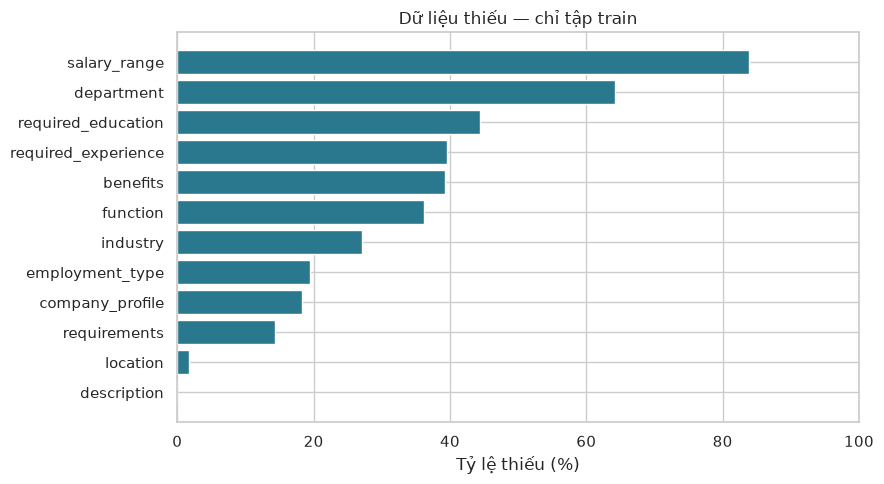

In [7]:
def make_features(frame):
    """Feature engineering theo từng dòng; cùng quy tắc cho train và tin mới."""
    result = pd.DataFrame(index=frame.index)
    cleaned_text = pd.DataFrame(index=frame.index)
    for col in TEXT_COLUMNS:
        series = frame[col].replace(r"^\s*$", np.nan, regex=True)
        cleaned = series.map(clean_text)
        cleaned_text[col] = cleaned
        result[f"{col}_missing"] = series.isna().astype(float)
        counts = cleaned.str.split().str.len().astype(float).mask(series.isna())
        result[f"{col}_word_count"] = counts
        result[f"log1p_{col}_word_count"] = np.log1p(counts)
    result["text_combined"] = cleaned_text.apply(
        lambda row: " ".join(part for part in row if part).strip(), axis=1
    )
    for col in BINARY_COLUMNS:
        values = pd.to_numeric(frame[col], errors="coerce")
        result[col] = values.where(values.isin([0, 1]), np.nan)
    result["salary_range_missing"] = (
        frame["salary_range"].replace(r"^\s*$", np.nan, regex=True).isna().astype(float)
    )
    for col in CATEGORICAL_COLUMNS:
        source = frame["location"].str.split(",").str[0] if col == "country" else frame[col]
        result[col] = source.str.strip().replace(r"^\s*$", np.nan, regex=True)
    return result


train_features = make_features(X_train)
train_missing = missing_report(X_train)
display(train_missing)
display(train_features[COUNT_COLUMNS].describe().T)
save_table(train_missing, "06_missing_train.csv")
save_table(train_features[COUNT_COLUMNS].describe().T, "06_word_count_describe_train.csv")

missing_to_plot = train_missing.loc[train_missing.missing_pct > 0].sort_values("missing_pct")
if not missing_to_plot.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(missing_to_plot.index, missing_to_plot["missing_pct"], color="#2A788E")
    ax.set(xlabel="Tỷ lệ thiếu (%)", title="Dữ liệu thiếu — chỉ tập train", xlim=(0, 100))
    finish_figure(fig, "06_missing_train.png")


## 6. Kiểm tra ngoại lai: phân phối và khoảng tứ phân vị (IQR)
Với Q1=phân vị 25%, Q3=phân vị 75%, IQR=Q3−Q1, đánh dấu quan sát ngoài
[Q1−1,5×IQR; Q3+1,5×IQR]. Mẫu số tỷ lệ ngoại lai là số quan sát **không thiếu**.
Không áp dụng IQR cho ID, nhãn hoặc cờ nhị phân. Nếu IQR=0, không tự gắn nhãn
outlier bằng quy tắc suy biến; ghi chú để kiểm tra thủ công.

Tin dài bất thường có thể hợp lệ hoặc mang thông tin về gian lận. Notebook chỉ
đánh dấu và mô tả, không tự xóa/cắt ngọn. Ngưỡng chỉ tính trên train.


,observed_count,Q1,Q3,IQR,lower,upper,outlier_count,outlier_pct,note
feature,,,,,,,,,
title_word_count,10836,2.0,4.0,2.0,-1.0,7.0,672,6.201550,Áp dụng IQR
company_profile_word_count,8849,54.0,148.0,94.0,-87.0,289.0,371,4.192564,Áp dụng IQR
description_word_count,10835,84.0,223.0,139.0,-124.5,431.5,392,3.617905,Áp dụng IQR
requirements_word_count,9276,38.0,118.0,80.0,-82.0,238.0,472,5.088400,Áp dụng IQR
benefits_word_count,6588,10.0,69.0,59.0,-78.5,157.5,288,4.371585,Áp dụng IQR


,job_id,fraudulent,title_word_count,company_profile_word_count,description_word_count,requirements_word_count,benefits_word_count
10,11,0,8.0,NaN,323.0,323.0,10.0
15,16,0,6.0,134.0,468.0,89.0,43.0
17,18,0,8.0,131.0,59.0,9.0,2.0
19,20,0,10.0,32.0,169.0,166.0,NaN
22,23,0,2.0,392.0,163.0,128.0,32.0
46,47,0,2.0,885.0,22.0,23.0,NaN
65,66,0,2.0,185.0,37.0,156.0,260.0
75,76,0,9.0,107.0,269.0,111.0,77.0
78,79,0,10.0,66.0,1151.0,NaN,NaN
94,95,0,11.0,131.0,100.0,15.0,2.0


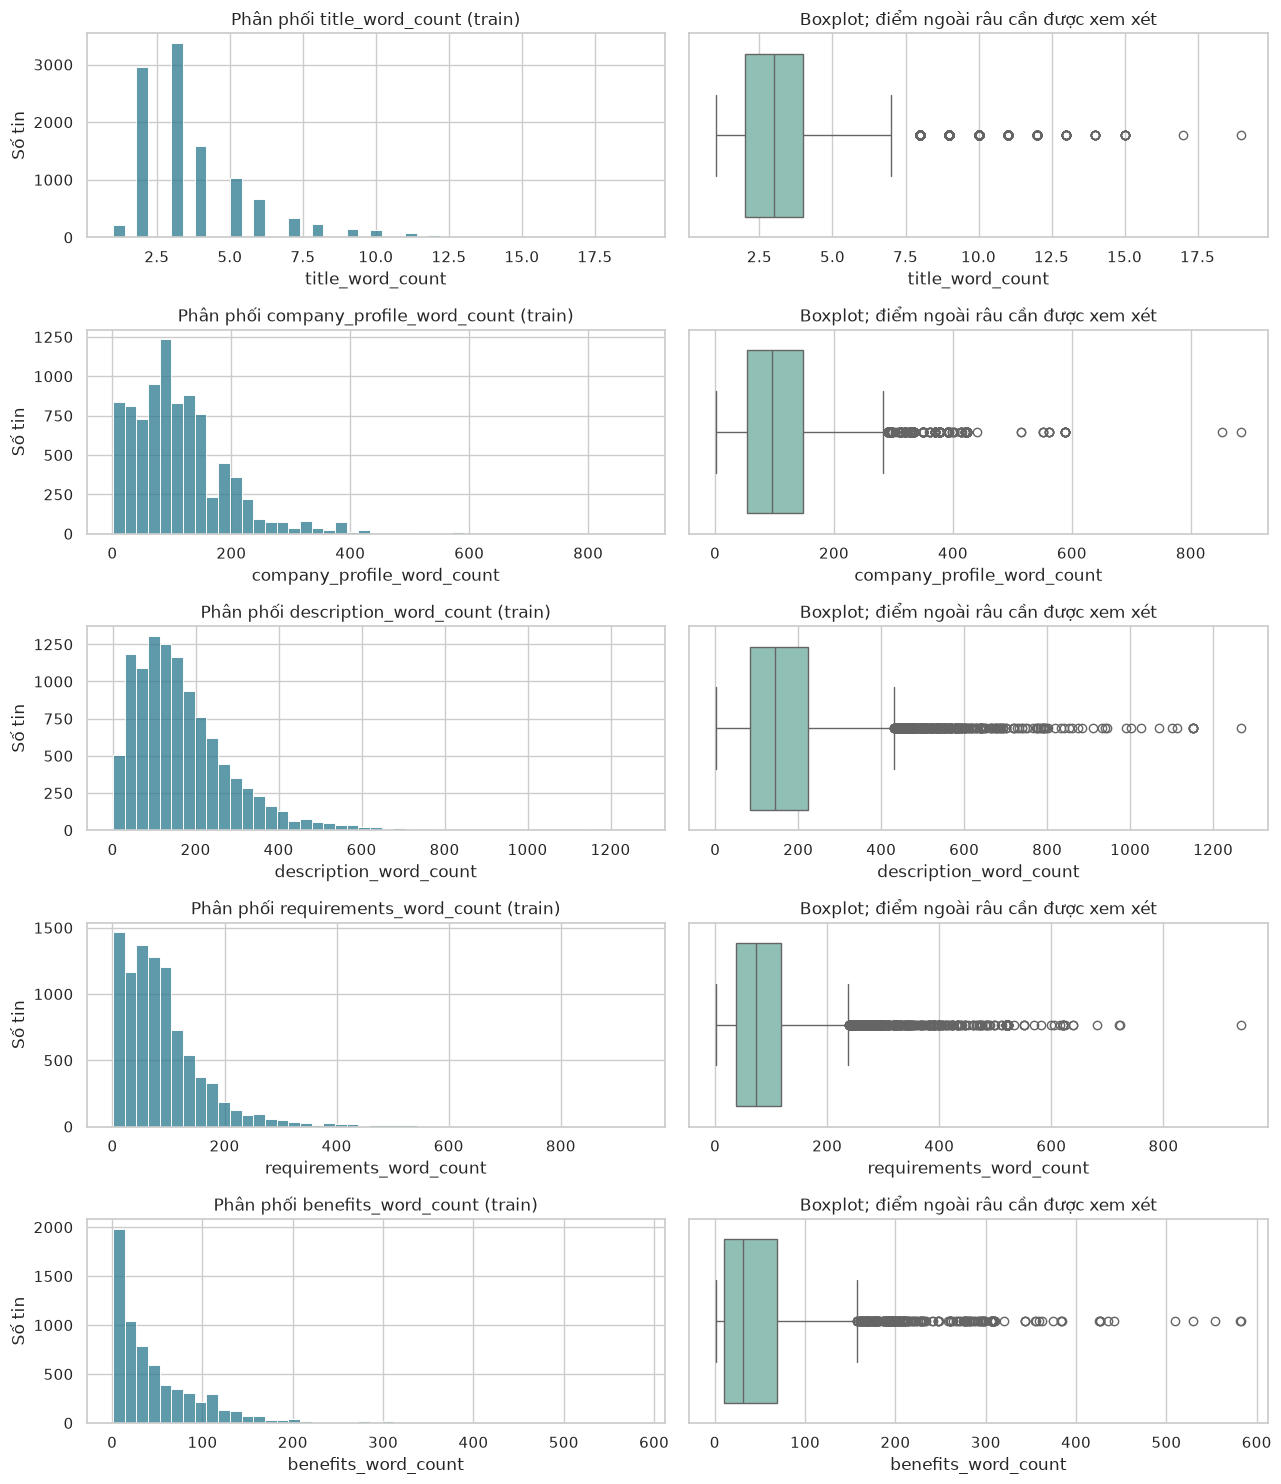

In [8]:
def iqr_report(frame, columns, factor=1.5):
    """Báo cáo IQR theo từng thuộc tính số và mặt nạ đánh dấu để truy vết."""
    records, masks = [], pd.DataFrame(False, index=frame.index, columns=columns)
    for col in columns:
        values = pd.to_numeric(frame[col], errors="coerce")
        observed = values.dropna()
        q1, q3 = observed.quantile([0.25, 0.75]) if len(observed) else (np.nan, np.nan)
        iqr = q3 - q1
        applicable = bool(len(observed) and iqr > 0)
        lower, upper = q1 - factor * iqr, q3 + factor * iqr
        if applicable:
            masks[col] = (values.lt(lower) | values.gt(upper)).fillna(False)
        count = int(masks[col].sum())
        records.append({
            "feature": col, "observed_count": len(observed), "Q1": q1, "Q3": q3,
            "IQR": iqr, "lower": lower, "upper": upper,
            "outlier_count": count if applicable else np.nan,
            "outlier_pct": 100 * count / len(observed) if applicable else np.nan,
            "note": "Áp dụng IQR" if applicable else "Thiếu toàn bộ hoặc IQR=0: rà soát",
        })
    return pd.DataFrame(records).set_index("feature"), masks


outlier_table, outlier_masks = iqr_report(train_features, COUNT_COLUMNS)
display(outlier_table)
save_table(outlier_table, "07_iqr_train.csv")
outlier_examples = parts["train"][[ID_COLUMN, TARGET]].join(train_features[COUNT_COLUMNS])
display(outlier_examples.loc[outlier_masks.any(axis=1)].head(10))

fig, axes = plt.subplots(len(COUNT_COLUMNS), 2, figsize=(13, 3 * len(COUNT_COLUMNS)))
for row, col in enumerate(COUNT_COLUMNS):
    sns.histplot(train_features[col].dropna(), bins=45, ax=axes[row, 0], color="#2A788E")
    axes[row, 0].set(title=f"Phân phối {col} (train)", ylabel="Số tin")
    sns.boxplot(x=train_features[col], ax=axes[row, 1], color="#88C7BB")
    axes[row, 1].set(title="Boxplot; điểm ngoài râu cần được xem xét")
finish_figure(fig, "07_outlier_distributions_train.png")


## 7. Trực quan hóa mất cân bằng lớp và tương quan
Biểu đồ đầu thể hiện kiểm kê nhãn dữ liệu gốc. Ma trận tương quan chỉ dùng train,
trên cờ nhị phân và số từ trước scaling, không đưa ID vào. Spearman phù hợp để
khảo sát quan hệ đơn điệu của số từ lệch; đây không phải bằng chứng quan hệ nhân quả.
pandas tính tương quan trên các cặp quan sát không thiếu; cột hằng có thể cho NaN.
Không mã hóa danh nghĩa bằng các số 0,1,2 rồi diễn giải tương quan số học.


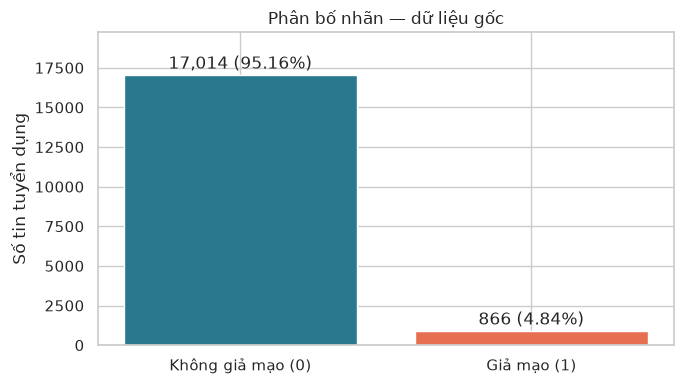

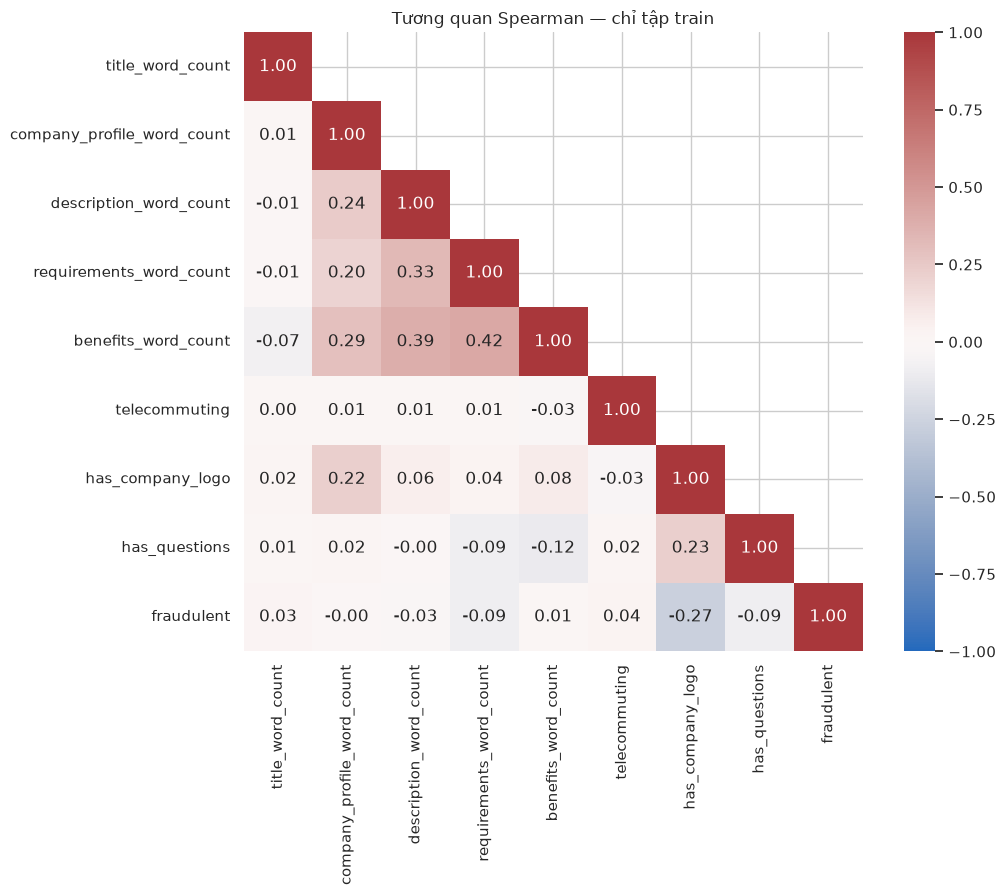

In [9]:
def plot_class_distribution(labels):
    report = class_report(labels)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(["Không giả mạo (0)", "Giả mạo (1)"], report["count"],
                  color=["#2A788E", "#E76F51"])
    for bar, count, pct in zip(bars, report["count"], report["percent"]):
        ax.annotate(f"{count:,} ({pct:.2f}%)", (bar.get_x() + bar.get_width()/2, count),
                    xytext=(0, 5), textcoords="offset points", ha="center")
    ax.set(title="Phân bố nhãn — dữ liệu gốc", ylabel="Số tin tuyển dụng")
    ax.set_ylim(0, report["count"].max() * 1.16)
    finish_figure(fig, "08_class_distribution_raw.png")


def plot_correlation(features, labels):
    numeric = features[COUNT_COLUMNS + BINARY_COLUMNS].copy()
    numeric[TARGET] = labels  # chỉ xuất hiện trong EDA; không đưa nhãn vào pipeline.
    corr = numeric.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(11, 9))
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
                annot=True, fmt=".2f", square=True, ax=ax)
    ax.set_title("Tương quan Spearman — chỉ tập train")
    finish_figure(fig, "09_correlation_train.png")
    return corr


plot_class_distribution(data[TARGET])
correlation_table = plot_correlation(train_features, y_train)
save_table(correlation_table, "09_correlation_train.csv")


## 8. Pipeline tiền xử lý không rò rỉ dữ liệu
**Số:** median của train → StandardScaler (z=(x−mean_train)/std_train).
**Danh nghĩa:** mode của train → One-hot; giá trị mới dùng handle_unknown="ignore".
Các nhóm hiếm được gộp theo tần suất train để hạn chế số chiều.
**Nhị phân/cờ thiếu:** mode của train, giữ giá trị 0/1.
**Văn bản:** làm sạch → ghép trường → TF-IDF unigram/bigram, tối đa 15.000 từ/cụm từ.

SimpleImputer giữ cột rỗng với keep_empty_features=True; cột hoàn toàn thiếu khi
fit sẽ có giá trị thay thế 0 theo hành vi thư viện. Báo cáo cột này để xem xét.
Nhãn đã là 0/1 nên không cần LabelEncoder. One-hot tránh áp đặt thứ tự giả lên
ngành nghề, học vấn, loại việc làm. Toàn bộ feature engineering nằm trong pipeline.

StandardScaler chỉ áp dụng cho nhánh số dẫn xuất. Ma trận TF-IDF giữ dạng thưa
để hạn chế bộ nhớ. Đầu ra phục vụ kế hoạch so sánh Logistic Regression, Linear SVM
và Random Forest ở giai đoạn tiếp theo.


In [10]:
def make_numeric_pipeline():
    """Median bền vững hơn mean trước đuôi phân phối dài; fit chỉ trên train."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ])


def make_categorical_pipeline():
    """Mode học từ train; OHE học danh mục/tần suất từ train, không từ test."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore", min_frequency=10, max_categories=60,
            sparse_output=True, dtype=np.float64,
        )),
    ])


def build_preprocessor():
    """Tạo pipeline MỚI mỗi lần; không tái sử dụng bộ đã fit để đánh giá CV."""
    columns = ColumnTransformer([
        ("numeric", make_numeric_pipeline(), NUMERIC_COLUMNS),
        ("categorical", make_categorical_pipeline(), CATEGORICAL_COLUMNS),
        ("flags", SimpleImputer(strategy="most_frequent", keep_empty_features=True), FLAG_COLUMNS),
        ("text", TfidfVectorizer(
            max_features=15000, ngram_range=(1, 2), min_df=3,
            sublinear_tf=True, strip_accents="unicode", dtype=np.float64,
        ), "text_combined"),  # tên cột dạng chuỗi => vector 1D cho TF-IDF.
    ], remainder="drop", sparse_threshold=1.0)
    return Pipeline([
        ("features", FunctionTransformer(make_features, validate=False)),
        ("columns", columns),
    ])


preprocessor = build_preprocessor()
X_train_ready = sparse.csr_matrix(preprocessor.fit_transform(X_train))
# Chụp trạng thái NGAY sau fit train để kiểm chứng transform không cập nhật mô hình.
train_column_transformer = preprocessor.named_steps["columns"]
train_numeric_pipeline = train_column_transformer.named_transformers_["numeric"]
median_after_fit = train_numeric_pipeline.named_steps["imputer"].statistics_.copy()
mean_after_fit = train_numeric_pipeline.named_steps["scaler"].mean_.copy()
vocabulary_after_fit = train_column_transformer.named_transformers_["text"].vocabulary_.copy()
# Không gọi fit/fit_transform cho validation hoặc test.
X_val_ready = sparse.csr_matrix(preprocessor.transform(X_val))
X_test_ready = sparse.csr_matrix(preprocessor.transform(X_test))

feature_names = preprocessor.named_steps["columns"].get_feature_names_out()
pd.Series(feature_names, name="feature").to_csv(
    ARTIFACT_DIR / "10_feature_names.csv", index=False, encoding="utf-8-sig"
)


## 9. Kiểm chứng tiền xử lý và thống kê minh chứng
Các kiểm tra dưới đây xác nhận: đủ dòng, cùng số cột, không có NaN/Inf, median
thực sự lấy từ train; transform không làm đổi median, trung bình hay từ vựng.
Chỉ chuyển một lát 5×12 sang dense để minh họa, không chuyển cả ma trận.


In [11]:
def matrix_summary(matrix, name):
    """Tính kích thước, mật độ và bộ nhớ thực tế của CSR, không densify."""
    return {
        "split": name, "rows": matrix.shape[0], "features": matrix.shape[1],
        "nonzero_values": matrix.nnz,
        "density_pct": 100 * matrix.nnz / (matrix.shape[0] * matrix.shape[1]),
        "csr_memory_mb": (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 2**20,
    }


matrices = {"train": X_train_ready, "validation": X_val_ready, "test": X_test_ready}
for name, matrix in matrices.items():
    assert matrix.shape[0] == len(parts[name])
    assert matrix.shape[1] == len(feature_names)
    assert np.isfinite(matrix.data).all(), f"NaN/Inf trong {name}"
assert TARGET not in X_train.columns and ID_COLUMN not in X_train.columns
assert not any(TARGET in name or ID_COLUMN in name for name in feature_names[:len(NUMERIC_COLUMNS)])

fitted_columns = preprocessor.named_steps["columns"]
numeric_pipe = fitted_columns.named_transformers_["numeric"]
cat_pipe = fitted_columns.named_transformers_["categorical"]
tfidf = fitted_columns.named_transformers_["text"]
expected_medians = train_features[NUMERIC_COLUMNS].median().fillna(0).to_numpy()
np.testing.assert_allclose(numeric_pipe.named_steps["imputer"].statistics_, expected_medians)
expected_imputed_train = train_features[NUMERIC_COLUMNS].fillna(
    train_features[NUMERIC_COLUMNS].median()
).fillna(0)
np.testing.assert_allclose(numeric_pipe.named_steps["scaler"].mean_, expected_imputed_train.mean())

# Một danh mục chưa thấy ở train phải transform được và không tạo thêm cột.
probe = X_val.iloc[:2].copy()
probe["industry"] = "__NEW_INDUSTRY_FOR_CHECK__"
probe_ready = preprocessor.transform(probe)
assert probe_ready.shape[1] == len(feature_names)
np.testing.assert_array_equal(median_after_fit, numeric_pipe.named_steps["imputer"].statistics_)
np.testing.assert_array_equal(mean_after_fit, numeric_pipe.named_steps["scaler"].mean_)
assert vocabulary_after_fit == tfidf.vocabulary_

numeric_statistics = pd.DataFrame({
    "median_train": numeric_pipe.named_steps["imputer"].statistics_,
    "mean_after_imputation_train": numeric_pipe.named_steps["scaler"].mean_,
    "scale_train": numeric_pipe.named_steps["scaler"].scale_,
}, index=NUMERIC_COLUMNS)
categorical_statistics = pd.DataFrame({
    "mode_train": cat_pipe.named_steps["imputer"].statistics_,
}, index=CATEGORICAL_COLUMNS)
matrix_report = pd.DataFrame([matrix_summary(m, n) for n, m in matrices.items()]).set_index("split")
display(numeric_statistics)
display(categorical_statistics)
display(matrix_report)
display(pd.DataFrame(X_train_ready[:5, :12].toarray(), columns=feature_names[:12]))
save_table(numeric_statistics, "11_numeric_fitted_statistics.csv")
save_table(categorical_statistics, "11_categorical_fitted_statistics.csv")
save_table(matrix_report, "11_matrix_summary.csv")
print("Đã kiểm tra: nhóm nội dung không giao nhau; ma trận hữu hạn; transform không học lại.")


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7792\3427751127.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame["salary_range"].replace(r"^\s*$", np.nan, regex=True).isna().astype(float)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7792\3427751127.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  result[col] = source.str.strip().replace(r"^\s*$", np.nan, regex=True)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7792\3427751127.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a 

,median_train,mean_after_imputation_train,scale_train
log1p_title_word_count,1.386294,1.480599,0.372646
log1p_company_profile_word_count,4.574711,4.457631,0.787724
log1p_description_word_count,4.969813,4.866686,0.786051
log1p_requirements_word_count,4.304065,4.189006,0.845137
log1p_benefits_word_count,3.465736,3.362651,0.951339


,mode_train
department,Sales
employment_type,Full-time
required_experience,Mid-Senior level
required_education,Bachelor's Degree
industry,Information Technology and Services
function,Information Technology
country,US


,rows,features,nonzero_values,density_pct,csr_memory_mb
split,,,,,
train,10836,15231,3782074,2.291567,43.323742
validation,3340,15231,1181285,2.322094,13.531479
test,3389,15231,1176387,2.279031,13.475613


,numeric__log1p_title_word_count,numeric__log1p_company_profile_word_count,numeric__log1p_description_word_count,numeric__log1p_requirements_word_count,numeric__log1p_benefits_word_count,categorical__department_Account Management,categorical__department_Accounting,categorical__department_Administration,categorical__department_Administrative,categorical__department_All,categorical__department_Business,categorical__department_Business Development
0,0.345742,0.632450,-1.189312,1.084959,0.108358,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.253067,1.117025,0.334855,0.367755,-2.077447,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.345742,0.743654,1.398714,-0.214963,1.406260,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.253067,1.022007,-3.911866,-0.426398,0.108358,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.923074,0.148631,1.162848,1.883406,-1.014103,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Đã kiểm tra: nhóm nội dung không giao nhau; ma trận hữu hạn; transform không học lại.


## 10. Xuất minh chứng và hướng sử dụng ở cuối kỳ
Notebook xuất bảng/biểu đồ ngay tại từng bước. Tùy chọn dưới đây lưu ma trận CSR
để xem lại; các ma trận đã fit trên toàn train **không được dùng làm đầu vào CV**.
Khi cross-validation, phải đặt `build_preprocessor()` và classifier trong cùng
Pipeline, truyền X thô để từng fold tự học imputation/OHE/scaling/TF-IDF.
Đồng thời dùng StratifiedGroupKFold với `train_groups` để giữ ranh giới nhóm.

Chưa oversample/SMOTE trong checkpoint này. Nếu áp dụng ở cuối kỳ, chỉ thực hiện
trong fold train; validation/test giữ phân bố tự nhiên. Chưa có metric phân lớp
vì chưa xây dựng mô hình. Tập test được giữ cho đánh giá cuối, không dùng để chọn
đặc trưng, thuật toán, siêu tham số hoặc ngưỡng cảnh báo.


In [12]:
SAVE_MATRICES = False  # Bật True nếu cần lưu đặc trưng đã biến đổi (có thể khá lớn).
if SAVE_MATRICES:
    for name, matrix in matrices.items():
        sparse.save_npz(ARTIFACT_DIR / f"X_{name}.npz", matrix)
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
        labels.to_csv(ARTIFACT_DIR / f"y_{name}.csv", index=True)

summary = {
    "source_file": str(DATA_PATH), "source_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "random_state": RANDOM_STATE, "versions": versions, "raw_shape": list(raw_data.shape),
    "raw_class_counts": {str(k): int(v) for k, v in data[TARGET].value_counts().items()},
    "duplicate_audit": {k: int(v) for k, v in duplicate_audit.items()},
    "split_summary": split_summary.to_dict(orient="index"),
    "output_features": len(feature_names), "fit_scope": "train only",
    "outlier_policy": "IQR audit on train; no automatic deletion or clipping",
    "model_training_performed": False,
    "cv_fold_audit": cv_audit.to_dict(orient="records"),
    "holdout_policy": "frozen data/split_manifest.csv",
    "cv_policy": "5-fold StratifiedGroupKFold, shuffle=False; audited before fitting",
}
(ARTIFACT_DIR / "12_run_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Thư mục minh chứng:", ARTIFACT_DIR.resolve())
print("Số tin giả ban đầu:", int(data[TARGET].sum()))
print("Tỷ lệ tin giả ban đầu:", f"{data[TARGET].mean():.2%}")
print("Checkpoint Data Understanding & Preprocessing đã chạy xong.")


Thư mục minh chứng: C:\Users\Lenovo\Documents\Codex\2026-09-22\b-n-l-m-t-chuy\outputs\Nhom7_TrackB_Midterm_dataset\midterm_artifacts
Số tin giả ban đầu: 866
Tỷ lệ tin giả ban đầu: 4.84%
Checkpoint Data Understanding & Preprocessing đã chạy xong.


## 11. Thảo luận và giới hạn

### Cơ sở lựa chọn phương pháp
- **Mất cân bằng lớp:** Accuracy của bộ dự đoán luôn chọn lớp đa số là mức đối chứng,
  không phản ánh khả năng phát hiện tin giả. Giai đoạn mô hình hóa sẽ đánh giá AP,
  Precision, Recall và F1 của lớp giả, kèm ROC-AUC và ma trận nhầm lẫn.
- **Giá trị thiếu:** số từ sau `log1p` dùng median; thuộc tính phân loại và cờ
  nhị phân dùng mode. Văn bản thiếu dùng chuỗi rỗng kèm cờ thiếu.
- **Ngoại lai:** quy tắc IQR phục vụ phát hiện và mô tả. Chưa loại hoặc cắt ngưỡng
  vì tin có nội dung dài bất thường vẫn có thể hợp lệ.
- **Kiểm soát rò rỉ:** tin có cùng nội dung chính nằm trong cùng tập. Thống kê,
  danh mục mã hóa và từ vựng chỉ học trên train. Khi kiểm định chéo, toàn bộ
  pipeline phải fit lại trong mỗi fold huấn luyện.

### Giới hạn
Nhãn được sử dụng theo bộ dữ liệu công bố. Khả năng khái quát sang tin tiếng Việt,
thời điểm mới hoặc doanh nghiệp mới chưa được kiểm chứng. Quy tắc nhóm hiện tại
chưa xử lý đầy đủ các tin gần trùng về ngữ nghĩa. Bộ nộp cố định phiên bản thư viện
đã kiểm thử để bảo đảm tính tái lập trong môi trường được khai báo.

### Kết quả giữa kỳ và công việc tiếp theo
Checkpoint đã hoàn thành khám phá dữ liệu, kiểm tra chất lượng, chia tập và xây dựng
pipeline tiền xử lý, kèm bảng thống kê và biểu đồ. Công việc tiếp theo là huấn luyện,
tinh chỉnh và so sánh mô hình, phân tích sai số, xây dựng ứng dụng minh họa.
Chưa có kết quả đánh giá mô hình phân lớp trong notebook này.

### Tài liệu kỹ thuật
- https://scikit-learn.org/1.7/common_pitfalls.html
- https://scikit-learn.org/1.7/modules/generated/sklearn.impute.SimpleImputer.html
- https://scikit-learn.org/1.7/modules/generated/sklearn.preprocessing.OneHotEncoder.html
- https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html


## 12. Giao diện huấn luyện dự kiến ở cuối kỳ
Hàm dưới đây chỉ định nghĩa cách ghép classifier với tiền xử lý, chưa gọi huấn luyện.
Truyền `X_train` thô cùng `cv_splits` đã kiểm toán vào GridSearchCV. Không truyền
`X_train_ready`, vì từ vựng/median của toàn train sẽ làm rò rỉ thông tin fold đánh giá.
Chọn cấu hình bằng Average Precision (AP), sau đó dùng validation chọn ngưỡng;
chỉ mở test sau khi khóa cả cấu hình và ngưỡng. Giữ mô hình fit trên train để không
làm thay đổi thang điểm sau khi chọn ngưỡng. Không refit train+validation trong
phép đánh giá test chính. Thử nghiệm triển khai refit là công việc riêng.


In [13]:
def make_model_pipeline(classifier):
    """Factory: mỗi lần gọi tạo toàn bộ tiền xử lý mới, tương thích sklearn.clone."""
    return Pipeline([("preprocess", build_preprocessor()), ("classifier", classifier)])

# Cuối kỳ: search = GridSearchCV(make_model_pipeline(classifier), param_grid,
#     scoring="average_precision", cv=cv_splits, refit=True, n_jobs=1)
# search.fit(X_train, y_train)  # chưa thực hiện trong checkpoint giữa kỳ.
